# Healing CAD at read time, and external tetrahedral meshers

Two capabilities that reach optional engines through the provider registry. `step.read(path, heal=True)` (and `iges.read`) runs OpenCASCADE's `ShapeFix_Shape`, then sews the faces at `sew_tolerance`, before the B-rep is extracted, and reports what changed. `tetrahedralize(surface, backend="tetgen")` or `backend="gmsh"` runs an installed TetGen or Gmsh program as a separate process on the surface and reads the tetrahedra back, the surface kept and checked. See `doc/formats/step.md` and `doc/tetrahedralize.md`.

In [1]:
import json
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    path = os.path.join(WORK, 'view.vtu')
    mp.write(path, mesh)
    return pv.read(path)


def render(panels, title, size=(1500, 560)):
    """Side-by-side PyVista renders embedded through matplotlib, a matplotlib
    fallback when GL is unavailable. A panel is (mesh, subtitle, red segments,
    clip): the segments an (n, 2, 3) array, clip cutting the mesh at x = 0."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, sub, segments, clip) in enumerate(panels):
            pl.subplot(0, i)
            grid = to_pyvista(mesh)
            if clip:
                grid = grid.clip(normal='x', origin=(0, 0, 0), crinkle=True)
            pl.add_mesh(grid, color='#2ec4b6', show_edges=True, edge_color='#1f4e79',
                        line_width=0.3)
            for a, b in segments:
                pl.add_mesh(pv.Line(a, b), color='#e63946', line_width=6)
            pl.add_text(sub, font_size=10)
            pl.camera_position = 'iso'
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 5.6))
        for i, (mesh, sub, segments, clip) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            tri = np.vstack([c.data for c in mesh.cells if c.type == 'triangle'])
            ax.plot_trisurf(*mesh.points.T, triangles=tri, color='#2ec4b6',
                            edgecolor='#1f4e79', linewidth=0.1)
            for a, b in segments:
                ax.plot(*np.array([a, b]).T, color='#e63946', linewidth=3)
            ax.set_title(sub); ax.set_axis_off()
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

ninja: warning: premature end of file; recovering


## A shared edge written twice

A common defect of exchanged CAD: two faces meet along an edge, but the file gives each face its own copy of it, a little apart (here `1e-4` mm), so the model is two loose faces. The STEP text below is written by hand for that reason: meshio++'s own writer shares edges by construction.

as written: 8 open edges
healed:     6 open edges
{
 "healed": true,
 "fixed": true,
 "sew_tolerance": 0.002236070660810387,
 "free_edges_before": 8,
 "free_edges_after": 6,
 "multiple_edges": 0,
 "degenerated": 0
}


2026-11-03 08:06:38.632 (   0.638s) [    7F1AAD391080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


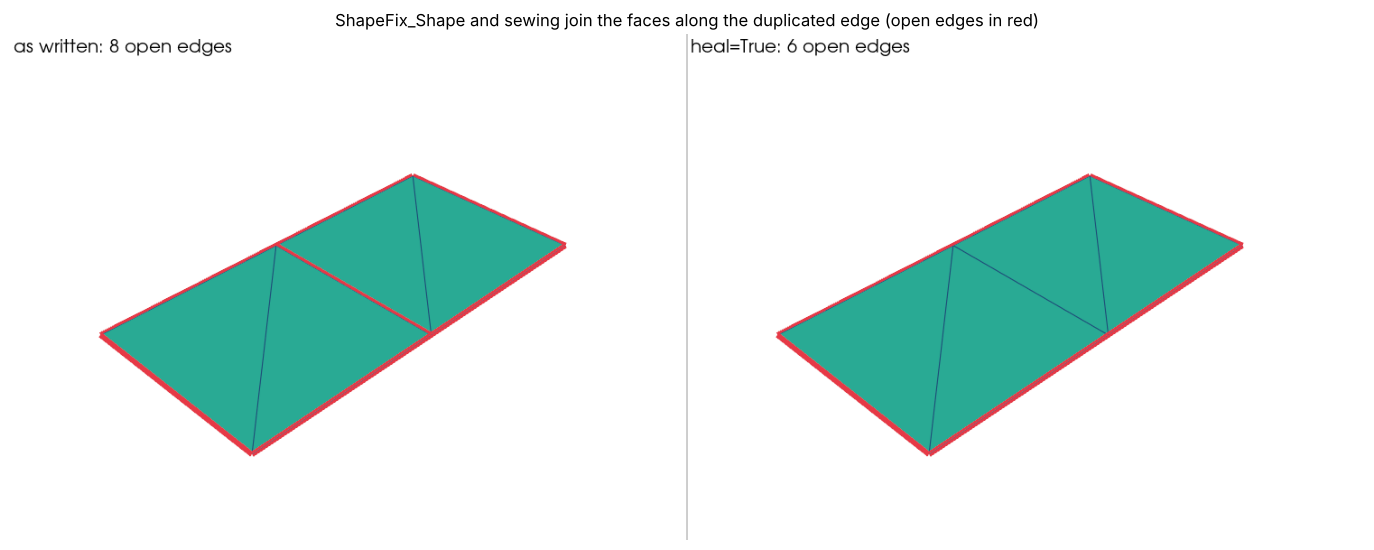

In [2]:
def two_face_step(gap):
    pts = [(0, 0, 0), (100, 0, 0), (100, 100, 0), (0, 100, 0),
           (100 + gap, 0, gap), (200, 0, 0), (200, 100, 0), (100 + gap, 100, gap)]
    out = []

    def ent(body):
        out.append(f'#{len(out) + 1}={body};')
        return len(out)

    def num(v):
        return f'{float(v):.17E}'  # a STEP real needs a decimal point in its mantissa

    def triple(v):
        return '(' + ','.join(num(c) for c in v) + ')'

    app = ent("APPLICATION_CONTEXT('core data for automotive mechanical design processes')")
    ent(f"APPLICATION_PROTOCOL_DEFINITION('international standard','automotive_design',2000,#{app})")
    pctx = ent(f"PRODUCT_CONTEXT('',#{app},'mechanical')")
    pdctx = ent(f"PRODUCT_DEFINITION_CONTEXT('part definition',#{app},'design')")
    prod = ent(f"PRODUCT('two','two','',(#{pctx}))")
    form = ent(f"PRODUCT_DEFINITION_FORMATION('','',#{prod})")
    pdef = ent(f"PRODUCT_DEFINITION('design','',#{form},#{pdctx})")
    pshape = ent(f"PRODUCT_DEFINITION_SHAPE('','',#{pdef})")
    length = ent('(LENGTH_UNIT()NAMED_UNIT(*)SI_UNIT(.MILLI.,.METRE.))')
    angle = ent('(NAMED_UNIT(*)PLANE_ANGLE_UNIT()SI_UNIT($,.RADIAN.))')
    solid = ent('(NAMED_UNIT(*)SI_UNIT($,.STERADIAN.)SOLID_ANGLE_UNIT())')
    unc = ent(f"UNCERTAINTY_MEASURE_WITH_UNIT(LENGTH_MEASURE(1.E-07),#{length},"
              "'distance_accuracy_value','confusion accuracy')")
    gctx = ent('(GEOMETRIC_REPRESENTATION_CONTEXT(3)GLOBAL_UNCERTAINTY_ASSIGNED_CONTEXT('
               f'(#{unc}))GLOBAL_UNIT_ASSIGNED_CONTEXT((#{length},#{angle},#{solid}))'
               "REPRESENTATION_CONTEXT('Context #1','3D Context'))")
    o = ent("CARTESIAN_POINT('',(0.,0.,0.))")
    z = ent("DIRECTION('',(0.,0.,1.))")
    x = ent("DIRECTION('',(1.,0.,0.))")
    origin = ent(f"AXIS2_PLACEMENT_3D('',#{o},#{z},#{x})")
    point = [ent(f"CARTESIAN_POINT('',{triple(p)})") for p in pts]
    vertex = [ent(f"VERTEX_POINT('',#{p})") for p in point]
    faces = []
    for f in range(2):
        loop = []
        for k in range(4):
            a, b = 4 * f + k, 4 * f + (k + 1) % 4
            d = np.subtract(pts[b], pts[a], dtype=float)
            ln = float(np.linalg.norm(d))
            direction = ent(f"DIRECTION('',{triple(d / ln)})")
            vec = ent(f"VECTOR('',#{direction},{num(ln)})")
            line = ent(f"LINE('',#{point[a]},#{vec})")
            edge = ent(f"EDGE_CURVE('',#{vertex[a]},#{vertex[b]},#{line},.T.)")
            oriented = ent(f"ORIENTED_EDGE('',*,*,#{edge},.T.)")
            loop.append(f'#{oriented}')
        el = ent(f"EDGE_LOOP('',({','.join(loop)}))")
        bound = ent(f"FACE_OUTER_BOUND('',#{el},.T.)")
        place = ent(f"AXIS2_PLACEMENT_3D('',#{point[4 * f]},#{z},#{x})")
        plane = ent(f"PLANE('',#{place})")
        face = ent(f"ADVANCED_FACE('',(#{bound}),#{plane},.T.)")
        faces.append(f'#{face}')
    shell = ent(f"OPEN_SHELL('',({','.join(faces)}))")
    model = ent(f"SHELL_BASED_SURFACE_MODEL('',(#{shell}))")
    rep = ent(f"MANIFOLD_SURFACE_SHAPE_REPRESENTATION('',(#{origin},#{model}),#{gctx})")
    ent(f'SHAPE_DEFINITION_REPRESENTATION(#{pshape},#{rep})')
    return ('ISO-10303-21;\nHEADER;\nFILE_DESCRIPTION((\'two faces\'),\'2;1\');\n'
            "FILE_NAME('two','1970-01-01T00:00:00',(''),(''),'','','');\n"
            "FILE_SCHEMA(('AUTOMOTIVE_DESIGN { 1 0 10303 214 1 1 1 1 }'));\nENDSEC;\nDATA;\n"
            + '\n'.join(out) + '\nENDSEC;\nEND-ISO-10303-21;\n')


step = os.path.join(WORK, 'two_faces.step')
with open(step, 'w') as f:
    f.write(two_face_step(1e-4))


def open_edges(mesh):
    """The B-rep edges bounding one face, as segments between their end control points."""
    out = []
    for e in mesh.info['brep']['edges']:
        if len(e['topology']) == 1 and e['curve'] is not None:
            cp = np.asarray(e['curve']['control_points'])
            out.append((cp[0, :3], cp[-1, :3]))
    return out


raw = mp.step.read(step)
healed = mp.step.read(step, heal=True)
print('as written:', len(open_edges(raw)), 'open edges')
print('healed:    ', len(open_edges(healed)), 'open edges')
print(json.dumps(json.loads(healed.info['brep']['extra'])['heal'], indent=1))
render([(raw, f'as written: {len(open_edges(raw))} open edges', open_edges(raw), False),
        (healed, f'heal=True: {len(open_edges(healed))} open edges', open_edges(healed), False)],
       'ShapeFix_Shape and sewing join the faces along the duplicated edge (open edges in red)')

A positive `sew_tolerance` sews without the `ShapeFix_Shape` pass; the record says which ran. The same options are `--heal` and `--sew-tolerance` on both CLIs' `convert` and `mesh-cad-surface`, `heal` and `sew_tolerance` on the MCP tools, `mio_cad_read_opts` in C, and `cadRead` in WebAssembly. A healed model meshes as one piece: `mesh_cad_surface` then shares the sewn edge between the faces, so the only open mesh edges left are the sheet's outer rim.

In [3]:
sewn = mp.step.read(step, sew_tolerance=1e-3)
print(json.loads(sewn.info['brep']['extra'])['heal'])
for name, model in (('as written', raw), ('healed', healed)):
    surface, report = mp.mesh_cad_surface(model, 20.0, return_report=True)
    print(f'{name:10s}: {report["num_points"]:3d} points, {report["num_open_edges"]} open mesh edges')
print('the rim of the 200 x 100 sheet at h = 20 is', (200 + 100) * 2 // 20, 'edges')

{'healed': False, 'fixed': False, 'sew_tolerance': 0.001, 'free_edges_before': 8, 'free_edges_after': 6, 'multiple_edges': 0, 'degenerated': 0}
as written:  86 points, 40 open mesh edges
healed    :  80 points, 30 open mesh edges
the rim of the 200 x 100 sheet at h = 20 is 30 edges


## TetGen and Gmsh as tetrahedral meshers

Besides Netgen and the native octree backend, `tetrahedralize` takes any registered mesher by name. Every native build registers `tetgen` and `gmsh` when those programs are installed (found on `PATH`, or through `MESHIOPLUSPLUS_TETGEN` and `MESHIOPLUSPLUS_GMSH`); they run as separate processes and are never linked, which is what their AGPL and GPL licences leave open. The core checks what they return: every input point back bit-equal, and the tetrahedra's one-sided faces the input's triangles.

backends: ['gmsh', 'octree', 'tetgen']


octree   15480 tets, boundary kept False, hausdorff 0.0072, dihedral 31.9 to 121.5, volume 4.1260
tetgen    4855 tets, boundary kept True, hausdorff 0.0000, dihedral 9.0 to 164.9, volume 4.1527


gmsh      5193 tets, boundary kept True, hausdorff 0.0000, dihedral 13.6 to 155.5, volume 4.1527


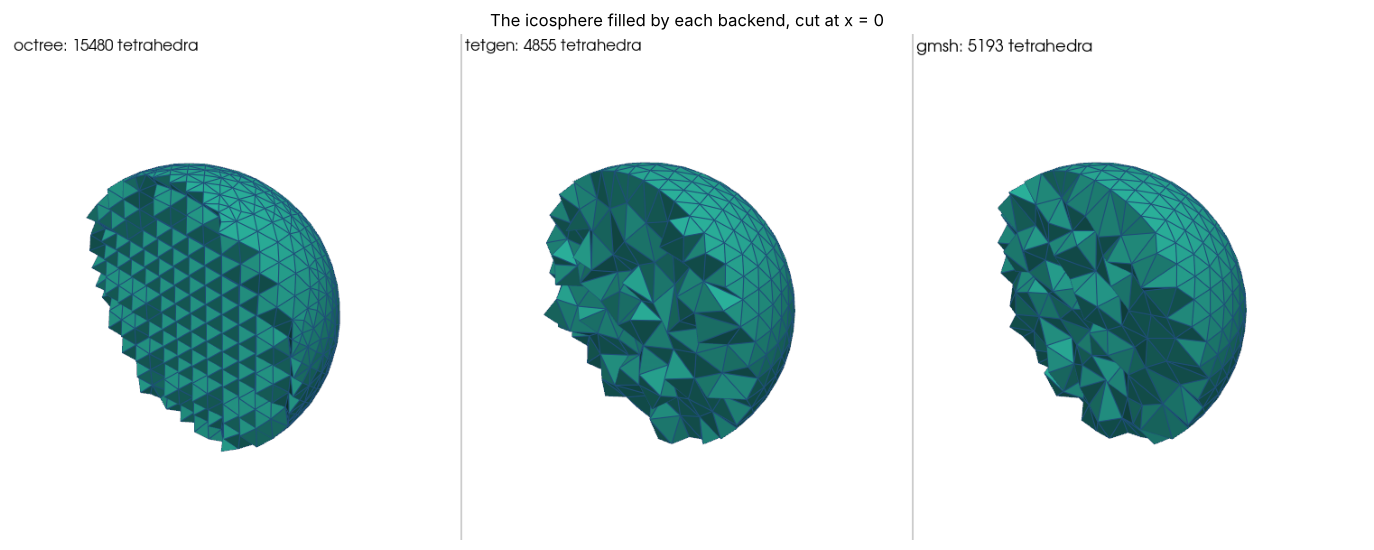

In [4]:
print('backends:', mp.tetrahedralize_backends())
skin = mp.icosa_sphere(1.0, 3)
panels = []
for backend in ['octree'] + [b for b in ('tetgen', 'gmsh') if b in mp.tetrahedralize_backends()]:
    volume, r = mp.tetrahedralize(skin, backend=backend, max_size=0.25, return_report=True)
    print(f'{backend:7s} {r["num_tetrahedra"]:6d} tets, boundary kept {r["boundary_preserved"]}, '
          f'hausdorff {r["hausdorff_to_surface"]:.4f}, dihedral {r["min_dihedral_deg"]:.1f} to '
          f'{r["max_dihedral_deg"]:.1f}, volume {r["volume"]:.4f}')
    tets = mp.Mesh(volume.points, [c for c in volume.cells if c.type == 'tetra'])
    panels.append((tets, f'{backend}: {r["num_tetrahedra"]} tetrahedra', [], True))
render(panels, 'The icosphere filled by each backend, cut at x = 0')

The same name works on every surface: `--backend tetgen` on both CLIs, the pipeline's `Backend`, `MIO_TETRAHEDRALIZE_BACKEND_NAMED` with `provider` in C, and the MCP tool, whose report lists `backends_available`. An unknown name is refused listing the ones this install has.

In [5]:
try:
    mp.tetrahedralize(skin, backend='no-such-mesher')
except NotImplementedError as exc:
    print(exc)

meshio++: tetrahedralize: no tetrahedral mesher named 'no-such-mesher' (available: auto, gmsh, octree, tetgen; tetgen and gmsh are found on PATH, or through MESHIOPLUSPLUS_TETGEN and MESHIOPLUSPLUS_GMSH)
